# 06 · Report maps

Publication-style figures (scale bar, north arrow, legend) saved to `outputs/figures/map_*.png`. The same layers are styled for QGIS in `qgis/` if you prefer to lay out maps there.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import numpy as np, pandas as pd, geopandas as gpd, rasterio, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch, Rectangle
from pyproj import Transformer
import config, classify as C

CRS = config.CRS_METRIC
prof = C.profile(); t = prof["transform"]
EXT = [t.c, t.c + t.a * prof["width"], t.f + t.e * prof["height"], t.f]
district = gpd.read_file(config.BOUNDARY_FILE).to_crs(CRS)
subs = gpd.read_file(config.DATA_PROCESSED / "nagaon_2022_subdistricts.geojson").to_crs(CRS)
assam = gpd.read_file(config.DATA_RAW / "boundary" / "datta07" / "ASSAM_DISTRICTS.geojson").to_crs(CRS)
st = C.static()

def scalebar(ax, length_km=10, loc=(0.06, 0.05)):
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    x = x0 + loc[0] * (x1 - x0); y = y0 + loc[1] * (y1 - y0); L = length_km * 1000
    for i in range(2):
        ax.add_patch(Rectangle((x + i * L / 2, y), L / 2, (y1 - y0) * 0.008, fc="k" if i == 0 else "w", ec="k", lw=0.6, zorder=10))
    for frac, lab in [(0, "0"), (0.5, f"{length_km // 2}"), (1, f"{length_km} km")]:
        ax.text(x + frac * L, y + (y1 - y0) * 0.018, lab, ha="center", fontsize=8, zorder=10)

def north(ax, loc=(0.94, 0.88)):
    ax.annotate("N", xy=loc, xytext=(loc[0], loc[1] - 0.08), xycoords="axes fraction", ha="center", fontsize=11,
                fontweight="bold", arrowprops=dict(arrowstyle="-|>", lw=1.5, color="k"))

def lonlat_ticks(ax, step=0.2):
    inv = Transformer.from_crs(CRS, "EPSG:4326", always_xy=True); fwd = Transformer.from_crs("EPSG:4326", CRS, always_xy=True)
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    lo0, la0 = inv.transform(x0, y0); lo1, la1 = inv.transform(x1, y1)
    lons = np.arange(np.ceil(lo0 / step) * step, lo1, step); lats = np.arange(np.ceil(la0 / step) * step, la1, step)
    yc = (y0 + y1) / 2; xc = (x0 + x1) / 2
    ax.set_xticks([fwd.transform(l, inv.transform(xc, yc)[1])[0] for l in lons], [f"{l:.1f}°E" for l in lons], fontsize=7)
    ax.set_yticks([fwd.transform(inv.transform(xc, yc)[0], l)[1] for l in lats], [f"{l:.1f}°N" for l in lats], fontsize=7)
    ax.tick_params(length=2)

def frame(ax):
    ax.set_xlim(EXT[0], EXT[1]); ax.set_ylim(EXT[2], EXT[3]); lonlat_ticks(ax)
    ax.set_xlabel(""); ax.set_ylabel("")

def outline(ax, labels=True):
    subs.boundary.plot(ax=ax, color="#666", lw=0.4, zorder=4)
    district.boundary.plot(ax=ax, color="k", lw=0.9, zorder=4)
    if labels:
        for _, s in subs.iterrows():
            c = s.geometry.representative_point()
            ax.annotate(s.sdtname, (c.x, c.y), ha="center", fontsize=8, color="#222",
                        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.6))

## Map 1 · Study area

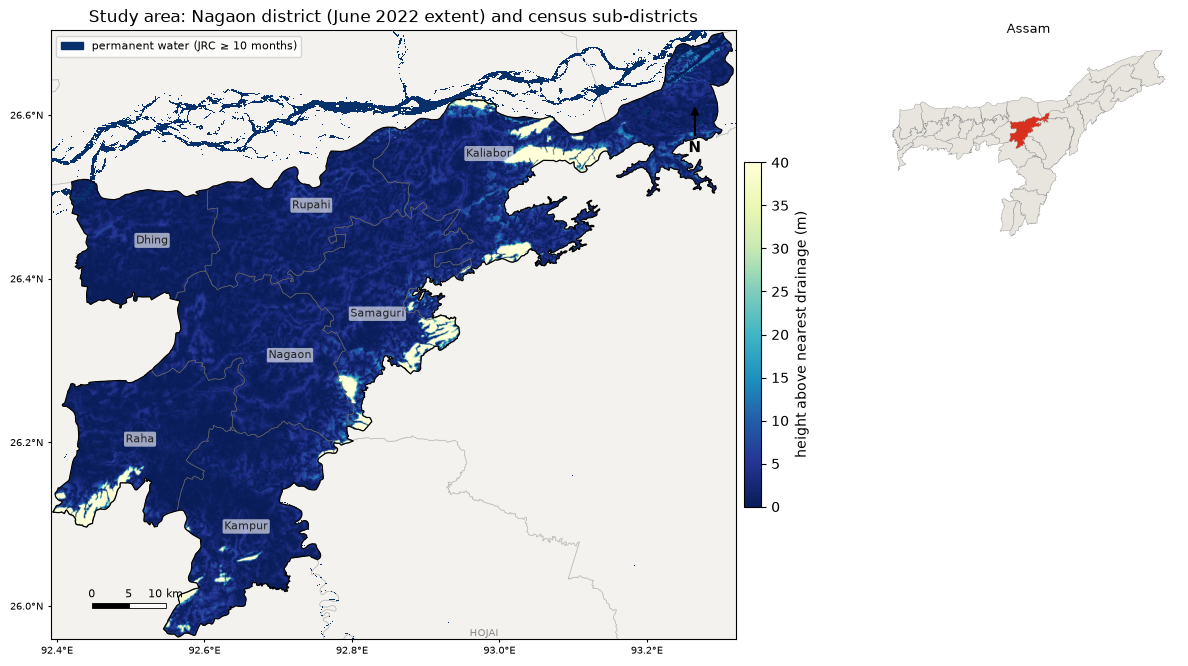

In [2]:
fig = plt.figure(figsize=(12, 8.5))
ax = fig.add_axes([0.05, 0.05, 0.68, 0.9])
assam.plot(ax=ax, color="#f4f2ee", edgecolor="#bbb", lw=0.5)
hand = np.where(st["district"], np.clip(st["hand"], 0, 40), np.nan)
im = ax.imshow(hand[::4, ::4], extent=EXT, cmap="YlGnBu_r", vmin=0, vmax=40, zorder=2)
perm = np.where(st["seasonality"] >= 10, 1, np.nan)
ax.imshow(perm[::2, ::2], extent=EXT, cmap=ListedColormap(["#08306b"]), interpolation="nearest", zorder=3)
outline(ax)
for _, d in assam.iterrows():
    if d.dtname in ("Morigaon", "Hojai", "Karbi Anglong", "Sonitpur", "Golaghat", "Biswanath", "Darrang", "West Karbi Anglong"):
        c = d.geometry.representative_point()
        if EXT[0] < c.x < EXT[1] and EXT[2] < c.y < EXT[3]:
            ax.annotate(d.dtname.upper(), (c.x, c.y), ha="center", fontsize=7, color="#888")
frame(ax); scalebar(ax); north(ax)
cb = fig.colorbar(im, ax=ax, shrink=0.45, pad=0.01); cb.set_label("height above nearest drainage (m)")
ax.set_title("Study area: Nagaon district (June 2022 extent) and census sub-districts")
ax.legend(handles=[Patch(color="#08306b", label="permanent water (JRC ≥ 10 months)")], loc="upper left", fontsize=8)
# inset: Assam with Nagaon highlighted
ia = fig.add_axes([0.74, 0.55, 0.25, 0.35])
assam.plot(ax=ia, color="#e8e5df", edgecolor="#999", lw=0.3)
district.plot(ax=ia, color="#d7301f")
ia.set_title("Assam", fontsize=9); ia.set_axis_off()
fig.savefig(config.OUT_FIGURES / "map_study_area.png", dpi=200, bbox_inches="tight"); plt.show()

## Map 2 · Flood extent on the two track-77 event dates

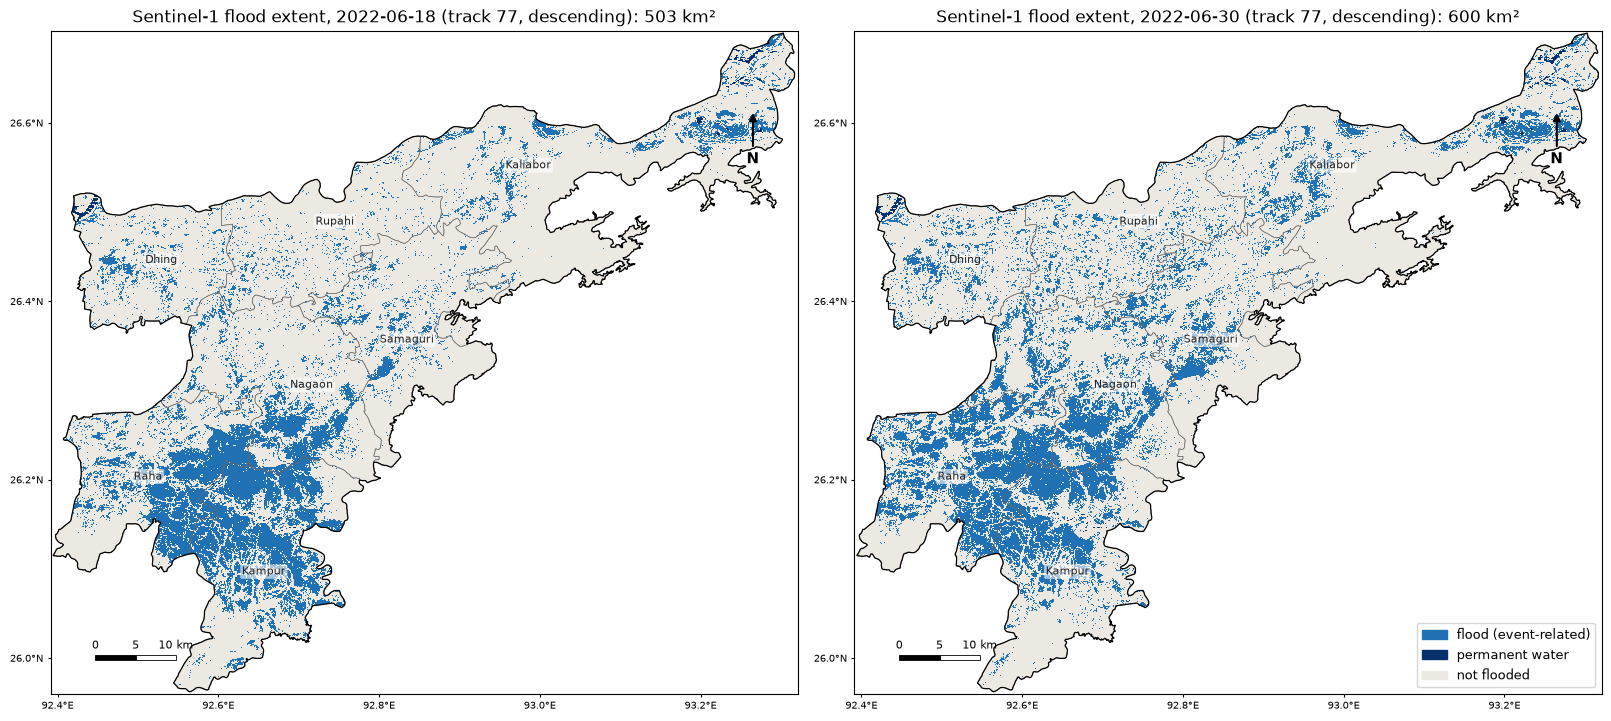

In [3]:
cmap = ListedColormap(["#ece9e2", "#2171b5", "#08306b"]); norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5], 3)
areas = pd.read_csv(config.OUT_TABLES / "flood_area_by_date.csv")
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), constrained_layout=True)
for ax, (date, orb) in zip(axes, [("2022-06-18", 77), ("2022-06-30", 77)]):
    with rasterio.open(config.OUT_RASTERS / f"flood_{date.replace('-', '')}_t{orb}.tif") as r:
        cl = r.read(1).astype(float)
    cl[cl == 255] = np.nan
    ax.imshow(cl[::3, ::3], extent=EXT, cmap=cmap, norm=norm, interpolation="nearest", zorder=2)
    outline(ax); frame(ax); scalebar(ax); north(ax)
    a = areas.query("date == @date").flood_km2.iloc[0]
    ax.set_title(f"Sentinel-1 flood extent, {date} (track {orb}, descending): {a:.0f} km²")
axes[1].legend(handles=[Patch(color="#2171b5", label="flood (event-related)"), Patch(color="#08306b", label="permanent water"),
                        Patch(color="#ece9e2", label="not flooded")], loc="lower right", fontsize=9)
fig.savefig(config.OUT_FIGURES / "map_flood_extent.png", dpi=200, bbox_inches="tight"); plt.show()

## Map 3 · How persistent was the flooding? (number of June dates flooded)

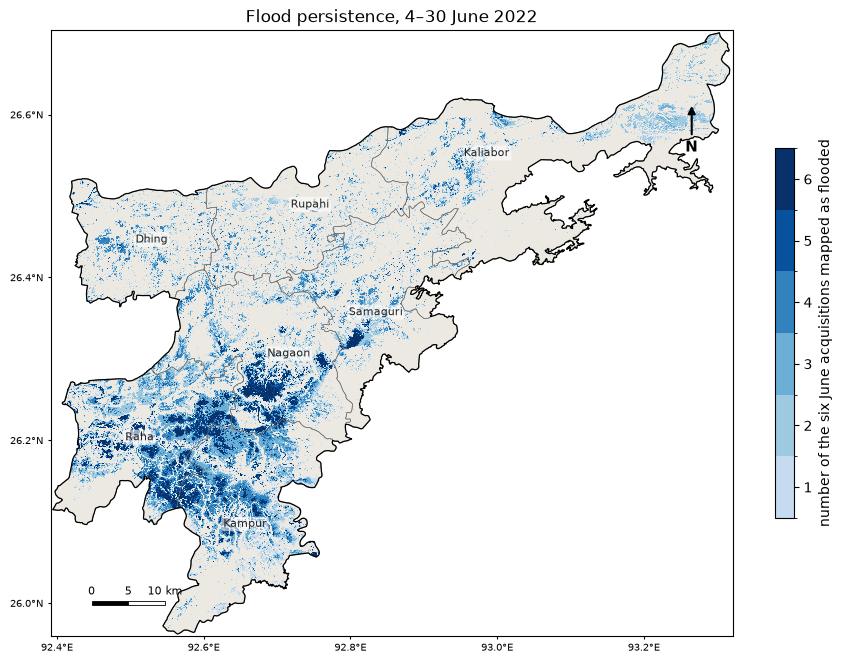

In [4]:
with rasterio.open(config.OUT_RASTERS / "flood_frequency_june2022.tif") as r:
    freq = r.read(1).astype(float)
freq[(freq == 255) | (freq == 0)] = np.nan
fig, ax = plt.subplots(figsize=(11, 8))
district.plot(ax=ax, color="#ece9e2")
cm = ListedColormap(["#c6dbef", "#9ecae1", "#6baed6", "#3182bd", "#08519c", "#08306b"])
im = ax.imshow(freq[::3, ::3], extent=EXT, cmap=cm, norm=BoundaryNorm(np.arange(0.5, 7.5), 6), interpolation="nearest", zorder=2)
outline(ax); frame(ax); scalebar(ax); north(ax)
cb = fig.colorbar(im, ax=ax, shrink=0.6, ticks=range(1, 7)); cb.set_label("number of the six June acquisitions mapped as flooded")
ax.set_title("Flood persistence, 4–30 June 2022")
fig.savefig(config.OUT_FIGURES / "map_flood_frequency.png", dpi=200, bbox_inches="tight"); plt.show()

## Map 4 · Built-up exposure (any June date), with a pixel-level zoom near Raha

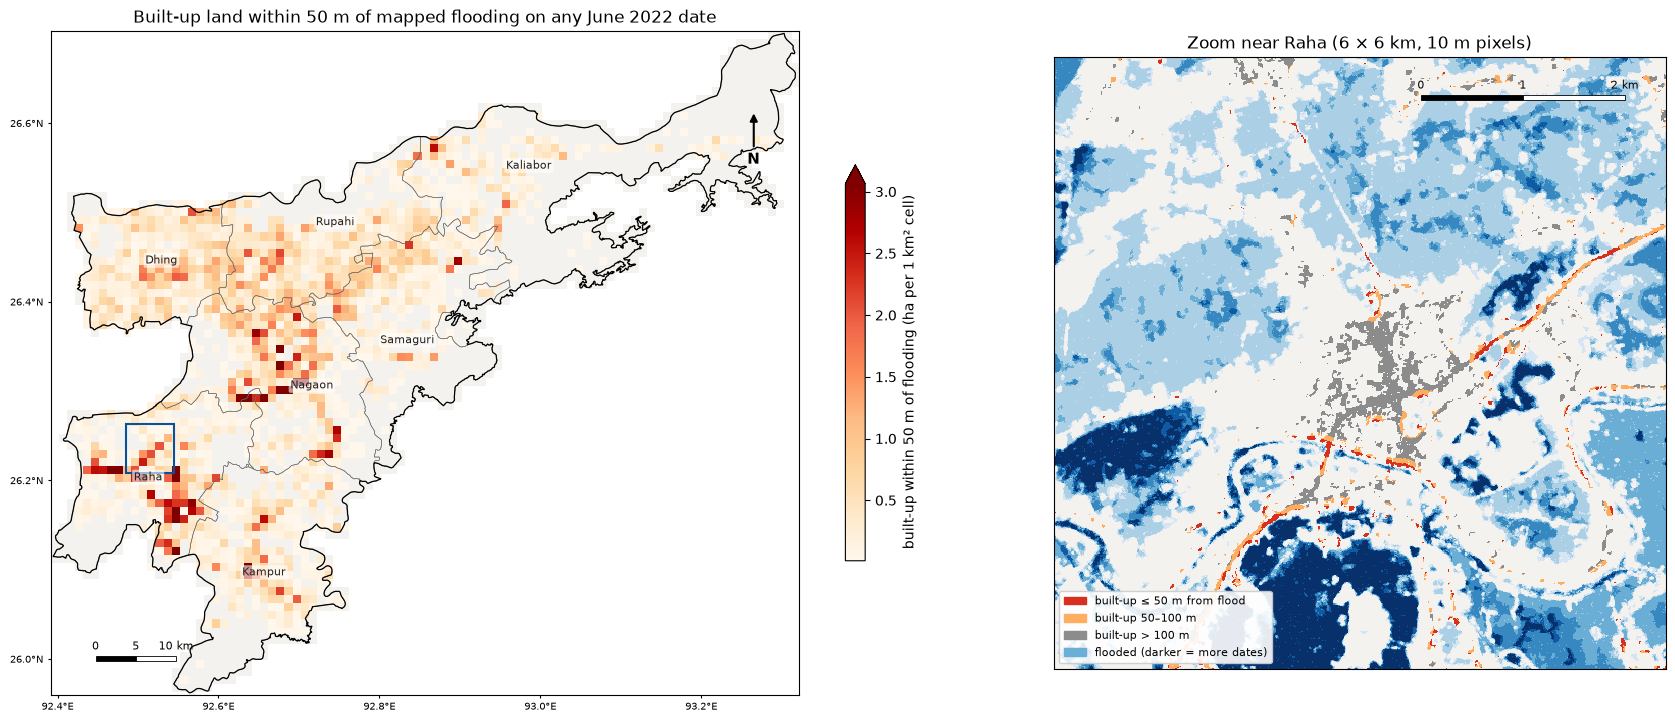

In [5]:
grid = gpd.read_file(config.DATA_PROCESSED / "exposure_grid_1km.gpkg")
grid["ha"] = grid.exposed_any_km2 * 100
with rasterio.open(config.OUT_RASTERS / "exposure_any_june2022.tif") as r:
    ex = r.read(1).astype(float)
with rasterio.open(config.OUT_RASTERS / "flood_frequency_june2022.tif") as r:
    fq = r.read(1)
fig = plt.figure(figsize=(17, 8))
ax = fig.add_axes([0.03, 0.05, 0.55, 0.9])
grid.plot(ax=ax, color="#f4f2ee", lw=0)
g = grid[grid.ha > 0]
g.plot(ax=ax, column="ha", cmap="OrRd", lw=0, legend=True, vmax=g.ha.quantile(0.99),
       legend_kwds={"label": "built-up within 50 m of flooding (ha per 1 km² cell)", "shrink": 0.55})
outline(ax); frame(ax); scalebar(ax); north(ax)
# zoom window near Raha town
fx, fy = Transformer.from_crs("EPSG:4326", CRS, always_xy=True).transform(92.515, 26.235)
W = 3000
ax.add_patch(Rectangle((fx - W, fy - W), 2 * W, 2 * W, fill=False, ec="#08519c", lw=1.5))
ax.set_title("Built-up land within 50 m of mapped flooding on any June 2022 date")
z = fig.add_axes([0.62, 0.1, 0.36, 0.8])
c0 = int((fx - W - t.c) / t.a); c1 = int((fx + W - t.c) / t.a)
r0 = int((t.f - (fy + W)) / -t.e); r1 = int((t.f - (fy - W)) / -t.e)
sub_fq = fq[r0:r1, c0:c1].astype(float); sub_fq[(sub_fq == 0) | (sub_fq == 255)] = np.nan
sub_ex = ex[r0:r1, c0:c1]
zext = [fx - W, fx + W, fy - W, fy + W]
z.imshow(np.zeros_like(sub_fq), extent=zext, cmap=ListedColormap(["#f4f2ee"]))
z.imshow(sub_fq, extent=zext, cmap="Blues", vmin=0, vmax=6, interpolation="nearest")
excol = np.full(sub_ex.shape + (4,), 0.0)
excol[sub_ex == 1] = (0.55, 0.55, 0.55, 1); excol[sub_ex == 2] = (0.99, 0.68, 0.38, 1); excol[sub_ex == 3] = (0.84, 0.19, 0.12, 1)
z.imshow(excol, extent=zext, interpolation="nearest")
z.set_xticks([]); z.set_yticks([]); z.set_title("Zoom near Raha (6 × 6 km, 10 m pixels)")
z.legend(handles=[Patch(color="#d7301f", label="built-up ≤ 50 m from flood"), Patch(color="#fdae61", label="built-up 50–100 m"),
                  Patch(color="#8c8c8c", label="built-up > 100 m"), Patch(color="#6baed6", label="flooded (darker = more dates)")],
         loc="lower left", fontsize=8, framealpha=0.9)
z.set_xlim(zext[0], zext[1]); z.set_ylim(zext[2], zext[3]); scalebar(z, length_km=2, loc=(0.6, 0.93))
fig.savefig(config.OUT_FIGURES / "map_exposure.png", dpi=200, bbox_inches="tight"); plt.show()